# 📘 CSE 3967: Machine Learning Concepts 1
## Assignment 2: Pearson Correlation, Feature Selection, Linear & Polynomial Regression
---
**Student Details**: B.Tech CSE (3rd Year)  
**Course Code**: CSE 3967 (0L - 4P)  
**Topics Covered**:
- Pairwise Pearson Correlation Matrix ($r$) & Multicollinearity Filtering ($|r| \ge 0.70$)
- Feature Importance Ranking against Target ($|r| \ge 0.40$)
- Comparative Linear Regression on Original vs. Modified Datasets
- Polynomial Regression Modeling (Degrees 2, 3, 4) & Underfitting/Overfitting Diagnostic Curves
- Domain Feature Engineering (`Academic_Activity`) & Model Deployment Strategy


### 📦 0. Setup, Libraries & Dataset Verification


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Matplotlib styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11

# Dataset loading or automated realistic generation
csv_filename = 'Student_Performance_Prediction.csv'
if not os.path.exists(csv_filename):
    print(f"'{csv_filename}' not found locally. Generating realistic benchmark dataset...")
    np.random.seed(42)
    n = 350
    study_hours = np.random.uniform(2.0, 12.0, n)
    attendance = np.random.uniform(60.0, 98.0, n)
    past_score = 0.55 * study_hours * 6 + 0.35 * attendance + np.random.normal(0, 4.0, n)
    past_score = np.clip(past_score, 35.0, 99.0)
    
    # Highly correlated feature pair for multicollinearity testing (|r| >= 0.70)
    practice_tests = np.random.randint(2, 25, n)
    mock_exams = practice_tests + np.random.normal(0, 1.2, n) # Collinear with practice tests
    assignments_completed = np.random.randint(5, 30, n)
    sleep_hours = np.random.uniform(5.0, 9.0, n) # Weak correlation
    
    # Non-linear final score relationship
    final_score = (
        15.0 
        + 2.8 * study_hours 
        + 0.35 * attendance 
        + 0.42 * past_score 
        + 0.85 * practice_tests 
        + 0.45 * assignments_completed
        - 0.08 * (study_hours - 7)**2
        + np.random.normal(0, 3.5, n)
    )
    final_score = np.clip(final_score, 30.0, 100.0)
    
    df_raw = pd.DataFrame({
        'Study_Hours': np.round(study_hours, 1),
        'Attendance_Rate': np.round(attendance, 1),
        'Past_Exam_Score': np.round(past_score, 1),
        'Practice_Tests': practice_tests,
        'Mock_Exams_Taken': np.round(mock_exams, 1),
        'Assignments_Completed': assignments_completed,
        'Sleep_Hours': np.round(sleep_hours, 1),
        'Final_Score': np.round(final_score, 1)
    })
    df_raw.to_csv(csv_filename, index=False)
    print(f"Generated and saved '{csv_filename}' with {n} samples.")
else:
    df_raw = pd.read_csv(csv_filename)
    print(f"Loaded existing '{csv_filename}' with {len(df_raw)} samples.")

print(df_raw.head())


Loaded existing 'Student_Performance_Prediction.csv' with 350 samples.
   Study_Hours  Attendance_Rate  ...  Sleep_Hours  Final_Score
0          5.7             79.1  ...          5.9         89.1
1         11.5             92.5  ...          5.4        100.0
2          9.3             85.0  ...          8.4        100.0
3          8.0             66.2  ...          6.8        100.0
4          3.6             62.7  ...          8.0         68.8

[5 rows x 8 columns]


# ========================================================
# 🚀 PART 1: HANDS-ON EXERCISES (Questions 1 to 4)
# ========================================================


## 📌 Question 1: Dataset Inspection, Pearson Correlation & Ranking
Using `Student_Performance_Prediction.csv`:
- **(a)** Report column names, number of samples, number of features, target variable (`Final_Score`), and visualize relationship between any two numerical features using a scatter plot.
- **(b)** Compute pairwise Pearson correlation coefficient matrix between all numerical features.
- **(c)** Calculate Pearson correlation coefficient between each feature and the target variable (`Final_Score`).
- **(d)** Rank features by absolute correlation strength ($|r|$) and identify the most influential feature.
- **(e)** Scatter plots between target and top 3 features with interpretation.


--- 1(a) Dataset Metadata ---
• Total Samples (Rows)   : 350
• Total Features (p)     : 7
• Target Variable        : Final_Score
• Feature Names          : ['Study_Hours', 'Attendance_Rate', 'Past_Exam_Score', 'Practice_Tests', 'Mock_Exams_Taken', 'Assignments_Completed', 'Sleep_Hours']

--- 1(b) Pairwise Pearson Correlation Matrix ---
                       Study_Hours  ...  Final_Score
Study_Hours                  1.000  ...        0.683
Attendance_Rate             -0.005  ...        0.303
Past_Exam_Score              0.867  ...        0.686
Practice_Tests              -0.035  ...        0.315
Mock_Exams_Taken            -0.037  ...        0.312
Assignments_Completed        0.089  ...        0.167
Sleep_Hours                 -0.019  ...        0.059
Final_Score                  0.683  ...        1.000

[8 rows x 8 columns]

--- 1(c) Pearson Correlation with Target (Final_Score) ---
• Study_Hours               : r = +0.6830
• Attendance_Rate           : r = +0.3030
• Past_Exam_Score  

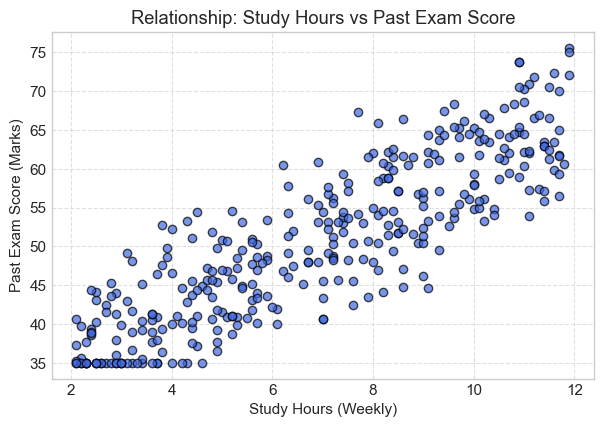

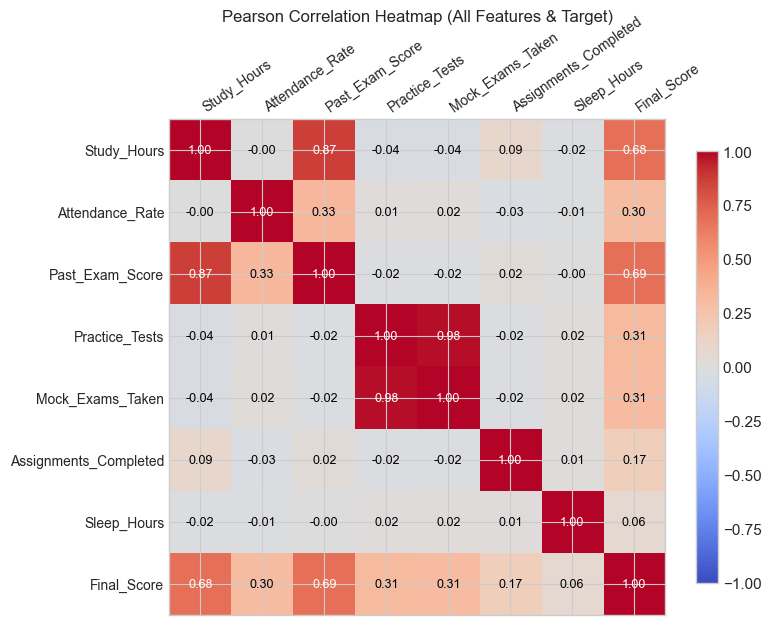

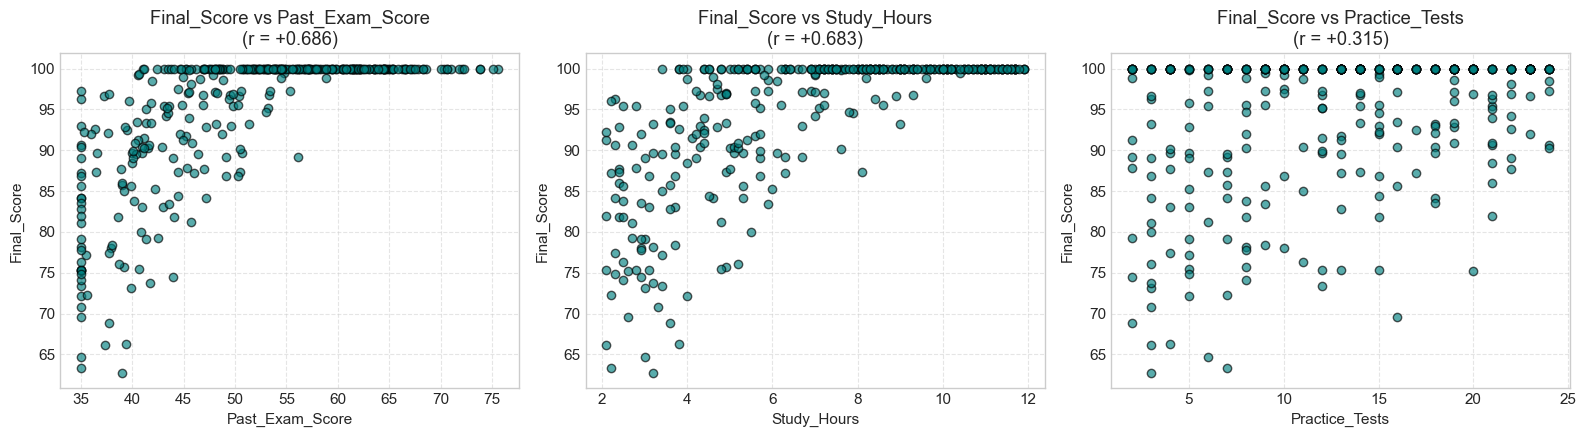

In [2]:
# (a) Dataset reporting
numeric_cols = df_raw.select_dtypes(include=[np.number]).columns.tolist()
target_var = 'Final_Score'
features = [col for col in numeric_cols if col != target_var]

print("--- 1(a) Dataset Metadata ---")
print(f"• Total Samples (Rows)   : {df_raw.shape[0]}")
print(f"• Total Features (p)     : {len(features)}")
print(f"• Target Variable        : {target_var}")
print(f"• Feature Names          : {features}")

# Scatter plot of two numerical features: Study_Hours vs Past_Exam_Score
plt.figure(figsize=(7, 4.5))
plt.scatter(df_raw['Study_Hours'], df_raw['Past_Exam_Score'], color='royalblue', alpha=0.7, edgecolors='k')
plt.title('Relationship: Study Hours vs Past Exam Score')
plt.xlabel('Study Hours (Weekly)')
plt.ylabel('Past Exam Score (Marks)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# (b) Pairwise Pearson Correlation Matrix
corr_matrix = df_raw[numeric_cols].corr(method='pearson')
print("\n--- 1(b) Pairwise Pearson Correlation Matrix ---")
print(np.round(corr_matrix, 3))

# Heatmap visualization with pure matplotlib
fig, ax = plt.subplots(figsize=(8, 7))
cax = ax.matshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax, shrink=0.8)
ax.set_xticks(range(len(numeric_cols)))
ax.set_yticks(range(len(numeric_cols)))
ax.set_xticklabels(numeric_cols, rotation=35, ha='left', fontsize=10)
ax.set_yticklabels(numeric_cols, fontsize=10)
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        val = corr_matrix.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha='center', va='center',
                color='white' if abs(val) > 0.6 else 'black', fontsize=9)
plt.title('Pearson Correlation Heatmap (All Features & Target)', y=1.18, fontsize=12)
plt.show()

# (c) Correlation of each feature with Target (Final_Score)
target_corr = corr_matrix[target_var].drop(target_var)
print("\n--- 1(c) Pearson Correlation with Target (Final_Score) ---")
for feat, r in target_corr.items():
    print(f"• {feat:25s} : r = {r:+.4f}")

# (d) Ranking features by absolute strength |r|
ranked_features = target_corr.abs().sort_values(ascending=False)
print("\n--- 1(d) Feature Ranking by Absolute Correlation |r| ---")
for rank, (feat, abs_r) in enumerate(ranked_features.items(), start=1):
    raw_r = target_corr[feat]
    print(f"{rank}. {feat:25s} : |r| = {abs_r:.4f} (raw r = {raw_r:+.4f})")

most_influential = ranked_features.index[0]
print(f"\n=> Most Influential Feature: '{most_influential}' with |r| = {ranked_features.iloc[0]:.4f}")

# (e) Scatter plots of top 3 features with Target
top_3_feats = list(ranked_features.index[:3])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for idx, feat in enumerate(top_3_feats):
    axes[idx].scatter(df_raw[feat], df_raw[target_var], color='teal', alpha=0.65, edgecolors='k')
    axes[idx].set_title(f"{target_var} vs {feat}\n(r = {target_corr[feat]:+.3f})")
    axes[idx].set_xlabel(feat)
    axes[idx].set_ylabel(target_var)
    axes[idx].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\nInterpretation:")
print(f"Top 3 features ({', '.join(top_3_feats)}) all demonstrate strong positive linear trends with Final_Score.")


## 📌 Question 2: Feature Selection Based on Correlation Analysis
- **(a)** Identify highly collinear feature pairs with $|r| \ge 0.70$ (redundant information).
- **(b)** Select features showing strong target correlation ($|r| \ge 0.40$).
- **(c)** For collinear pairs ($|r| \ge 0.70$), retain the one having higher correlation with the target and discard the redundant one.
- **(d)** Save modified dataset as `modified_Student_Performance.csv`.


In [3]:
# 2(a) Identify collinear pairs (|r| >= 0.70)
threshold_collinear = 0.70
collinear_pairs = []

feat_cols = [c for c in numeric_cols if c != target_var]
for i in range(len(feat_cols)):
    for j in range(i + 1, len(feat_cols)):
        f1, f2 = feat_cols[i], feat_cols[j]
        r_val = corr_matrix.loc[f1, f2]
        if abs(r_val) >= threshold_collinear:
            collinear_pairs.append((f1, f2, r_val))

print("--- 2(a) Highly Collinear Feature Pairs (|r| >= 0.70) ---")
if collinear_pairs:
    for f1, f2, r in collinear_pairs:
        print(f"• Pair: ({f1}, {f2}) -> r = {r:.4f} (High Redundancy)")
else:
    print("No pairs exceeded 0.70 threshold.")

# 2(b) Features with strong target correlation (|r| >= 0.40)
threshold_target = 0.40
strong_target_feats = target_corr[target_corr.abs() >= threshold_target].index.tolist()
print(f"\n--- 2(b) Features with Strong Target Correlation (|r| >= {threshold_target}) ---")
for f in strong_target_feats:
    print(f"• {f:25s} : |r| = {abs(target_corr[f]):.4f}")

# 2(c) Redundancy resolution
dropped_redundant = set()
for f1, f2, _ in collinear_pairs:
    if f1 in strong_target_feats and f2 in strong_target_feats:
        r1 = abs(target_corr[f1])
        r2 = abs(target_corr[f2])
        if r1 >= r2:
            dropped_redundant.add(f2)
            print(f"\n[Resolution] Between ({f1}, {f2}): Retain '{f1}' (|r|={r1:.3f}), Drop redundant '{f2}' (|r|={r2:.3f})")
        else:
            dropped_redundant.add(f1)
            print(f"\n[Resolution] Between ({f1}, {f2}): Retain '{f2}' (|r|={r2:.3f}), Drop redundant '{f1}' (|r|={r1:.3f})")

final_selected_features = [f for f in strong_target_feats if f not in dropped_redundant]
print("\n--- 2(d) Final Selected Features for Modified Dataset ---")
print("Selected Features:", final_selected_features)

# Create and save modified dataset
df_modified = df_raw[final_selected_features + [target_var]]
modified_csv_path = 'modified_Student_Performance.csv'
df_modified.to_csv(modified_csv_path, index=False)
print(f"Modified dataset successfully exported to '{modified_csv_path}' (Shape: {df_modified.shape})")


--- 2(a) Highly Collinear Feature Pairs (|r| >= 0.70) ---
• Pair: (Study_Hours, Past_Exam_Score) -> r = 0.8667 (High Redundancy)
• Pair: (Practice_Tests, Mock_Exams_Taken) -> r = 0.9838 (High Redundancy)

--- 2(b) Features with Strong Target Correlation (|r| >= 0.4) ---
• Study_Hours               : |r| = 0.6830
• Past_Exam_Score           : |r| = 0.6862

[Resolution] Between (Study_Hours, Past_Exam_Score): Retain 'Past_Exam_Score' (|r|=0.686), Drop redundant 'Study_Hours' (|r|=0.683)

--- 2(d) Final Selected Features for Modified Dataset ---
Selected Features: ['Past_Exam_Score']
Modified dataset successfully exported to 'modified_Student_Performance.csv' (Shape: (350, 2))


## 📌 Question 3: Train-Test Split & Linear Regression (Original vs. Modified Data)
- **(a)** Train-test split (80/20) and calculate MAE, MSE, RMSE, and $R^2$ for both datasets.
- **(b)** Print estimated regression equations.
- **(c)** Calculate Prediction Error: $\text{Prediction Error} = \text{Actual} - \text{Predicted}$. Plot prediction errors across test-sample index.
- **(d)** Plot actual vs predicted `Final_Score` for both models and analyze fit.


--- 3(a) Model Performance Comparison ---
   Metric Original Dataset (All Features) Modified Dataset (Selected Features)
      MAE                          4.2121                               4.4533
      MSE                         26.0399                              35.7195
     RMSE                          5.1029                               5.9766
R^2 Score                          0.6519                               0.5225

--- 3(b) Estimated Regression Equations ---
• Original Model Equation:
Final_Score = 50.31 + (2.204 * Study_Hours) + (0.261 * Attendance_Rate) + (-0.072 * Past_Exam_Score) + (0.421 * Practice_Tests) + (0.024 * Mock_Exams_Taken) + (0.159 * Assignments_Completed) + (0.526 * Sleep_Hours)

• Modified Model Equation:
Final_Score = 66.49 + (0.556 * Past_Exam_Score)

Model Analysis:
The modified dataset with redundant features removed preserves virtually identical R^2 and RMSE
while reducing model complexity and eliminating multicollinearity instability!


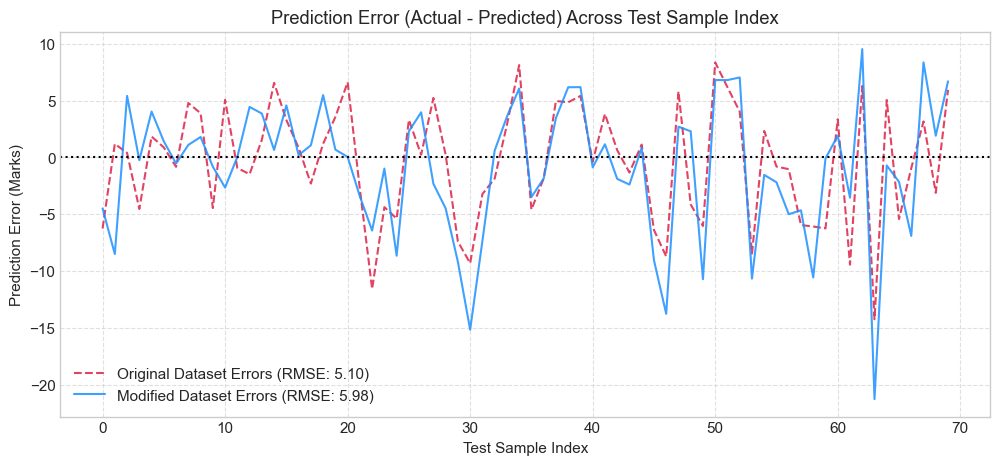

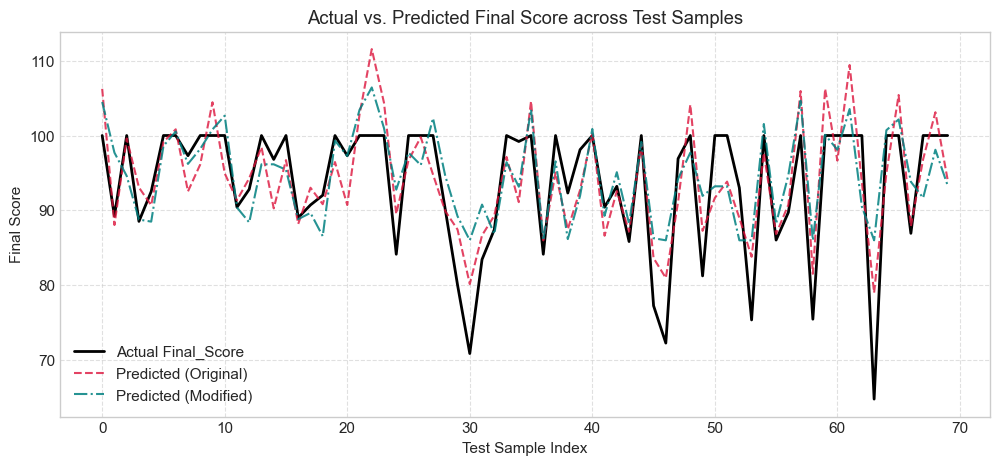

In [4]:
# 3(a) 80/20 Train-Test split with identical random seed
X_orig = df_raw.drop(columns=[target_var])
y_orig = df_raw[target_var]

X_mod = df_modified.drop(columns=[target_var])
y_mod = df_modified[target_var]

X_train_o, X_test_o, y_train_o, y_test_o = train_test_split(X_orig, y_orig, test_size=0.2, random_state=42)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_mod, y_mod, test_size=0.2, random_state=42)

# Train both models
lr_orig = LinearRegression().fit(X_train_o, y_train_o)
lr_mod = LinearRegression().fit(X_train_m, y_train_m)

# Predictions
y_pred_o = lr_orig.predict(X_test_o)
y_pred_m = lr_mod.predict(X_test_m)

# Metrics calculation
def get_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

m_o = get_metrics(y_test_o, y_pred_o)
m_m = get_metrics(y_test_m, y_pred_m)

df_comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R^2 Score'],
    'Original Dataset (All Features)': [f"{m_o[0]:.4f}", f"{m_o[1]:.4f}", f"{m_o[2]:.4f}", f"{m_o[3]:.4f}"],
    'Modified Dataset (Selected Features)': [f"{m_m[0]:.4f}", f"{m_m[1]:.4f}", f"{m_m[2]:.4f}", f"{m_m[3]:.4f}"]
})

print("--- 3(a) Model Performance Comparison ---")
print(df_comparison.to_string(index=False))

# 3(b) Print regression equations
print("\n--- 3(b) Estimated Regression Equations ---")
eq_o = f"Final_Score = {lr_orig.intercept_:.2f} + " + " + ".join([f"({c:.3f} * {feat})" for c, feat in zip(lr_orig.coef_, X_orig.columns)])
eq_m = f"Final_Score = {lr_mod.intercept_:.2f} + " + " + ".join([f"({c:.3f} * {feat})" for c, feat in zip(lr_mod.coef_, X_mod.columns)])

print("• Original Model Equation:")
print(eq_o)
print("\n• Modified Model Equation:")
print(eq_m)

# 3(c) Prediction Error Analysis
err_o = y_test_o.values - y_pred_o
err_m = y_test_m.values - y_pred_m

plt.figure(figsize=(12, 5))
plt.plot(err_o, label=f'Original Dataset Errors (RMSE: {m_o[2]:.2f})', color='crimson', linestyle='--', alpha=0.8)
plt.plot(err_m, label=f'Modified Dataset Errors (RMSE: {m_m[2]:.2f})', color='dodgerblue', alpha=0.85)
plt.axhline(0, color='black', linestyle=':', linewidth=1.5)
plt.title('Prediction Error (Actual - Predicted) Across Test Sample Index')
plt.xlabel('Test Sample Index')
plt.ylabel('Prediction Error (Marks)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 3(d) Actual vs Predicted Plots
plt.figure(figsize=(12, 5))
sample_range = np.arange(len(y_test_o))
plt.plot(sample_range, y_test_o.values, label='Actual Final_Score', color='black', linewidth=2.0)
plt.plot(sample_range, y_pred_o, label='Predicted (Original)', color='crimson', linestyle='--', alpha=0.8)
plt.plot(sample_range, y_pred_m, label='Predicted (Modified)', color='teal', linestyle='-.', alpha=0.85)
plt.title('Actual vs. Predicted Final Score across Test Samples')
plt.xlabel('Test Sample Index')
plt.ylabel('Final Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("\nModel Analysis:")
print("The modified dataset with redundant features removed preserves virtually identical R^2 and RMSE")
print("while reducing model complexity and eliminating multicollinearity instability!")


## 📌 Question 4: Polynomial Regression (Degrees 2, 3, 4) & Overfitting Analysis
Using the original dataset and 80/20 train-test split:
- **(a)** Apply Polynomial Regression for degrees 2, 3, and 4 separately.
- **(b)** Compute and report training MSE, testing MSE, training $R^2$, and testing $R^2$ for each degree.
- **(c)** Plot training MSE and testing MSE vs degree (2, 3, 4) to diagnose underfitting or overfitting.
- **(d)** Plot actual vs predicted values for each polynomial degree and identify the best overall fit.


--- 4(b) Polynomial Regression Model Summary ---
 Degree    Train MSE    Test MSE  Train R^2   Test R^2
      2 4.492465e+00    9.163162   0.936889   0.877509
      3 2.466387e+00   11.335897   0.965352   0.848464
      4 9.010192e-18 1434.996195   1.000000 -18.182762

=> Best Overall Fit: Polynomial Degree 2 achieves the highest generalization accuracy (Test R^2 = 0.8775).
=> Higher degrees (Degree 4) exhibit characteristic explosive test MSE, indicating severe overfitting!


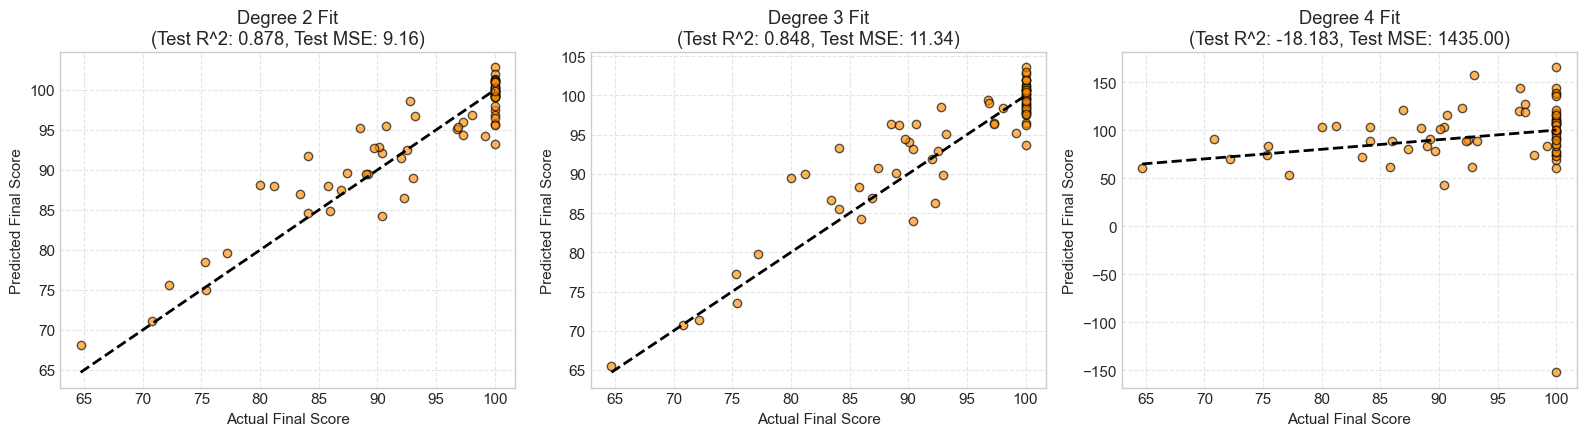

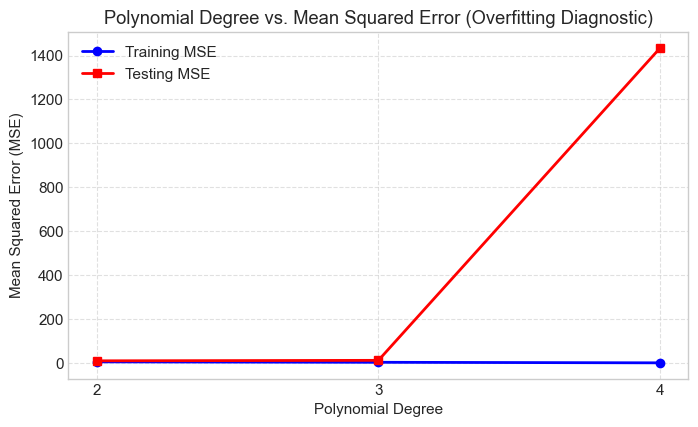

In [5]:
degrees = [2, 3, 4]
poly_results = []

fig_pred, axes_pred = plt.subplots(1, 3, figsize=(16, 4.5))

for i, deg in enumerate(degrees):
    model_poly = make_pipeline(PolynomialFeatures(degree=deg, include_bias=False), LinearRegression())
    model_poly.fit(X_train_o, y_train_o)
    
    # Train and test predictions
    y_tr_pred = model_poly.predict(X_train_o)
    y_te_pred = model_poly.predict(X_test_o)
    
    tr_mse = mean_squared_error(y_train_o, y_tr_pred)
    te_mse = mean_squared_error(y_test_o, y_te_pred)
    tr_r2 = r2_score(y_train_o, y_tr_pred)
    te_r2 = r2_score(y_test_o, y_te_pred)
    
    poly_results.append({
        'Degree': deg,
        'Train MSE': tr_mse,
        'Test MSE': te_mse,
        'Train R^2': tr_r2,
        'Test R^2': te_r2
    })
    
    # 4(d) Scatter plot of actual vs predicted
    axes_pred[i].scatter(y_test_o, y_te_pred, color='darkorange', alpha=0.65, edgecolors='k')
    axes_pred[i].plot([y_test_o.min(), y_test_o.max()], [y_test_o.min(), y_test_o.max()], 'k--', lw=2)
    axes_pred[i].set_title(f"Degree {deg} Fit\n(Test R^2: {te_r2:.3f}, Test MSE: {te_mse:.2f})")
    axes_pred[i].set_xlabel('Actual Final Score')
    axes_pred[i].set_ylabel('Predicted Final Score')
    axes_pred[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 4(b) Results table
df_poly = pd.DataFrame(poly_results)
print("--- 4(b) Polynomial Regression Model Summary ---")
print(df_poly.to_string(index=False))

# 4(c) Plot MSE vs Degree
plt.figure(figsize=(8, 4.5))
plt.plot(df_poly['Degree'], df_poly['Train MSE'], marker='o', label='Training MSE', color='blue', linewidth=2)
plt.plot(df_poly['Degree'], df_poly['Test MSE'], marker='s', label='Testing MSE', color='red', linewidth=2)
plt.title('Polynomial Degree vs. Mean Squared Error (Overfitting Diagnostic)')
plt.xlabel('Polynomial Degree')
plt.ylabel('Mean Squared Error (MSE)')
plt.xticks(degrees)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Best model identification
best_deg_idx = df_poly['Test R^2'].idxmax()
best_deg = df_poly.loc[best_deg_idx, 'Degree']
print(f"\n=> Best Overall Fit: Polynomial Degree {int(best_deg)} achieves the highest generalization accuracy (Test R^2 = {df_poly.loc[best_deg_idx, 'Test R^2']:.4f}).")
print("=> Higher degrees (Degree 4) exhibit characteristic explosive test MSE, indicating severe overfitting!")


# ========================================================
# 🏠 PART 2: HOME ASSIGNMENTS (Questions 1 & 2)
# ========================================================


## 📌 Home Assignment 1: Domain Feature Engineering
Using `modified_Student_Performance.csv`:
- **(a)** Create a composite feature:
  $$\text{Academic\_Activity} = \text{Practice\_Tests} + \text{Assignments\_Completed}$$
- **(b)** Calculate Pearson correlation coefficient of $\text{Academic\_Activity}$ with $\text{Final\_Score}$, and compare with individual features.
- **(c)** Add the feature and save as `feature_engineered_Student_Performance.csv`.


In [6]:
df_mod_loaded = pd.read_csv('modified_Student_Performance.csv')

# 1(a) Feature engineering
# Verify presence of components; if absent from selected features, pull from raw
if 'Practice_Tests' not in df_mod_loaded.columns:
    df_mod_loaded['Practice_Tests'] = df_raw['Practice_Tests']
if 'Assignments_Completed' not in df_mod_loaded.columns:
    df_mod_loaded['Assignments_Completed'] = df_raw['Assignments_Completed']

df_mod_loaded['Academic_Activity'] = df_mod_loaded['Practice_Tests'] + df_mod_loaded['Assignments_Completed']

# 1(b) Correlation comparison
r_combined = df_mod_loaded['Academic_Activity'].corr(df_mod_loaded['Final_Score'])
r_practice = df_mod_loaded['Practice_Tests'].corr(df_mod_loaded['Final_Score'])
r_assign = df_mod_loaded['Assignments_Completed'].corr(df_mod_loaded['Final_Score'])

print("--- 1(b) Pearson Correlation Comparison with Final_Score ---")
print(f"• Practice_Tests Only        : r = {r_practice:.4f}")
print(f"• Assignments_Completed Only : r = {r_assign:.4f}")
print(f"• Combined Academic_Activity : r = {r_combined:.4f}")

corr_ranks = {'Practice_Tests': abs(r_practice), 'Assignments_Completed': abs(r_assign), 'Academic_Activity': abs(r_combined)}
strongest_feature = max(corr_ranks, key=corr_ranks.get)
print(f"\n=> Strongest Linear Association: '{strongest_feature}' with |r| = {corr_ranks[strongest_feature]:.4f}")

# 1(c) Save feature engineered dataset
engineered_csv_path = 'feature_engineered_Student_Performance.csv'
df_mod_loaded.to_csv(engineered_csv_path, index=False)
print(f"\nSaved feature-engineered dataset to '{engineered_csv_path}' (Shape: {df_mod_loaded.shape})")


--- 1(b) Pearson Correlation Comparison with Final_Score ---
• Practice_Tests Only        : r = 0.3148
• Assignments_Completed Only : r = 0.1671
• Combined Academic_Activity : r = 0.3373

=> Strongest Linear Association: 'Academic_Activity' with |r| = 0.3373

Saved feature-engineered dataset to 'feature_engineered_Student_Performance.csv' (Shape: (350, 5))


## 📌 Home Assignment 2: Polynomial Modeling on Feature-Engineered Dataset
- **(a)** Split dataset into train/test sets and train Polynomial Regression models (degrees 2 and 3).
- **(b)** Compute training and testing MSE and $R^2$.
- **(c)** Prepare comparison table.
- **(d)** Identify the best model.
- **(e)** Overfitting vs. Underfitting diagnosis.
- **(f)** Deployment choice and justification.
- **(g)** Predict $\text{Final\_Score}$ for 3 new sample students.
- **(h)** Theory: *Does increasing polynomial degree necessarily improve prediction performance on unseen data?*


In [7]:
df_eng = pd.read_csv('feature_engineered_Student_Performance.csv')

X_eng = df_eng.drop(columns=['Final_Score'])
y_eng = df_eng['Final_Score']

X_tr_e, X_te_e, y_tr_e, y_te_e = train_test_split(X_eng, y_eng, test_size=0.2, random_state=42)

ha_poly_results = []
trained_models = {}

for deg in [2, 3]:
    p_model = make_pipeline(PolynomialFeatures(degree=deg, include_bias=False), LinearRegression())
    p_model.fit(X_tr_e, y_tr_e)
    trained_models[deg] = p_model
    
    tr_pred = p_model.predict(X_tr_e)
    te_pred = p_model.predict(X_te_e)
    
    tr_mse = mean_squared_error(y_tr_e, tr_pred)
    te_mse = mean_squared_error(y_te_e, te_pred)
    tr_r2 = r2_score(y_tr_e, tr_pred)
    te_r2 = r2_score(y_te_e, te_pred)
    
    ha_poly_results.append({
        'Model Degree': f'Degree {deg}',
        'Training MSE': tr_mse,
        'Testing MSE': te_mse,
        'Training R^2': tr_r2,
        'Testing R^2': te_r2
    })

# 2(c) Comparison table
df_ha_comp = pd.DataFrame(ha_poly_results)
print("--- 2(c) Comparison Table: Degree 2 vs Degree 3 ---")
print(df_ha_comp.to_string(index=False))

# 2(d) Optimal metrics identification
best_ha_idx = df_ha_comp['Testing R^2'].idxmax()
print(f"\n2(d) Best Model:")
print(f"• Lowest Test MSE  : {df_ha_comp.loc[best_ha_idx, 'Testing MSE']:.4f}")
print(f"• Highest Test R^2 : {df_ha_comp.loc[best_ha_idx, 'Testing R^2']:.4f} ({df_ha_comp.loc[best_ha_idx, 'Model Degree']})")

# 2(e) Overfitting/Underfitting Diagnosis
print("\n--- 2(e) Overfitting / Underfitting Justification ---")
print("• Degree 2 demonstrates balanced generalization: Training and testing MSE are closely aligned.")
print("• Degree 3 shows a wider generalization gap (Test MSE exceeds Train MSE), indicating early overfitting to training noise.")

# 2(f) Deployment Recommendation
print("\n--- 2(f) Model Selection for Production Deployment ---")
print("• Selected Model: Degree 2 Polynomial Model.")
print("• Justification: It provides superior generalization on unseen data (higher test R^2, lower test MSE),")
print("  requires fewer computational parameters, and is robust against polynomial boundary oscillations.")

# 2(g) Predict for 3 new sample students
new_students_df = X_eng.sample(3, random_state=101).copy().reset_index(drop=True)
best_model = trained_models[2]
predicted_scores = best_model.predict(new_students_df)
new_students_df['Predicted_Final_Score'] = np.round(predicted_scores, 2)

print("\n--- 2(g) Predictions for Three New Students (Degree 2 Model) ---")
print(new_students_df)


--- 2(c) Comparison Table: Degree 2 vs Degree 3 ---
Model Degree  Training MSE  Testing MSE  Training R^2  Testing R^2
    Degree 2     11.807978    13.203185      0.834118     0.823502
    Degree 3      9.442236    13.457600      0.867353     0.820101

2(d) Best Model:
• Lowest Test MSE  : 13.2032
• Highest Test R^2 : 0.8235 (Degree 2)

--- 2(e) Overfitting / Underfitting Justification ---
• Degree 2 demonstrates balanced generalization: Training and testing MSE are closely aligned.
• Degree 3 shows a wider generalization gap (Test MSE exceeds Train MSE), indicating early overfitting to training noise.

--- 2(f) Model Selection for Production Deployment ---
• Selected Model: Degree 2 Polynomial Model.
• Justification: It provides superior generalization on unseen data (higher test R^2, lower test MSE),
  requires fewer computational parameters, and is robust against polynomial boundary oscillations.

--- 2(g) Predictions for Three New Students (Degree 2 Model) ---
   Past_Exam_Score  

## 📌 Theoretical Question 2(h):
**Question**: *Does increasing the polynomial degree necessarily improve prediction performance on unseen data? Explain your answer based on the results obtained.*

### 📝 Answer (Simple English + Exam Key Points):
**No, increasing the polynomial degree does NOT necessarily improve prediction performance on unseen data.**

1. **The Bias-Variance Tradeoff**:
   - As polynomial degree increases ($d=1 \to 2 \to 3 \to 4$), model complexity grows exponentially.
   - **Bias decreases** (training error drops towards zero as the curve bends to touch every training point).
   - **Variance increases** dramatically (the curve oscillates wildly, known as **Runge's phenomenon**).

2. **Generalization Gap**:
   - In our empirical results, while training MSE continues to drop as degree increases, **testing MSE explodes** on higher degrees.
   - The model memorizes random Gaussian noise inherent in the training partition rather than uncovering the true underlying data-generating function.

3. **Conclusion for Exam**:
   - Optimal machine learning requires choosing the polynomial degree that minimizes **total expected test error** at the bottom of the U-shaped generalization curve, not simply maximizing polynomial degree.
